<a href="https://colab.research.google.com/github/shanchepngen-ux/ML-For-Engineering/blob/main/Assignment_Week_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Week 5: Building a Supervised Machine Learning Model

### Target and input features

The input features are the 14 channels in each Landslide4Sense image patch, which contain remote-sensing and topographic information. The output target is the corresponding landslide mask, where pixel values indicate the labelled landslide status.

### Problem type

For this experiment, the mask values are treated as numerical targets, and the task is formulated as a regression problem. Linear Regression and a Decision Tree Regressor are trained to estimate the mask value from the input channels. Because the original target is a binary mask, classification models would be more natural for the underlying landslide-segmentation task.

### Training and testing

The labelled image patches are divided into training and testing sets. The models learn from the training patches and make predictions on patches held out for testing. This helps evaluate how well they generalize to unseen image patches.


### Limitations and relevance to my project

The dataset provides remote-sensing and topographic information associated with landslide masks. It is useful for exploring supervised learning, but it does not directly represent artisanal mining pit collapses. Future work would require mining-specific information, including rainfall, soil and geological properties, pit geometry, surface displacement, and reliable records of collapse and non-collapse events.


In [ ]:
!pip -q install huggingface_hub h5py scikit-learn

In [ ]:
from huggingface_hub import hf_hub_download
import os

repo_id = "ibm-nasa-geospatial/Landslide4sense"
local_dir = "/content/Landslide4Sense"

os.makedirs(local_dir, exist_ok=True)

# Download 100 training images and their matching masks
for i in range(1, 101):
    hf_hub_download(
        repo_id=repo_id,
        repo_type="dataset",
        filename=f"images/train/image_{i}.h5",
        local_dir=local_dir
    )

    hf_hub_download(
        repo_id=repo_id,
        repo_type="dataset",
        filename=f"annotations/train/mask_{i}.h5",
        local_dir=local_dir
    )

print("Download complete!")

images/train/image_1.h5: reconstructing file:   0%|          |  0.00B / 1.84MB            

images/train/image_1.h5: downloading bytes:           |  0.00B            

annotations/train/mask_1.h5: reconstructing file:   0%|          |  0.00B / 18.4kB            

annotations/train/mask_1.h5: downloading bytes:           |  0.00B            

images/train/image_2.h5: reconstructing file:   0%|          |  0.00B / 1.84MB            

...

images/train/image_100.h5: reconstructing file:   0%|          |  0.00B / 1.84MB            

images/train/image_100.h5: downloading bytes:           |  0.00B            

annotations/train/mask_100.h5: reconstructing file:   0%|          |  0.00B / 18.4kB            

annotations/train/mask_100.h5: downloading bytes:           |  0.00B            

Download complete!


In [ ]:
import glob

image_folder = "/content/Landslide4Sense/images/train"
mask_folder = "/content/Landslide4Sense/annotations/train"

image_paths = glob.glob(os.path.join(image_folder, "*.h5"))
mask_paths = glob.glob(os.path.join(mask_folder, "*.h5"))

print("Number of image files:", len(image_paths))
print("Number of mask files:", len(mask_paths))

print("\nFirst image:", image_paths[0] if image_paths else "None")
print("First mask:", mask_paths[0] if mask_paths else "None")

Number of image files: 100
Number of mask files: 100

First image: /content/Landslide4Sense/images/train/image_39.h5
First mask: /content/Landslide4Sense/annotations/train/mask_36.h5


In [ ]:
import h5py
import numpy as np

all_values = set()

for path in mask_paths:
    with h5py.File(path, "r") as f:
        mask = f["mask"][:]
        all_values.update(np.unique(mask).tolist())

print("Target values across downloaded masks:", sorted(all_values))

Target values across downloaded masks: [0, 1]


In [ ]:
import os
import glob
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

IMAGE_DIR = "/content/Landslide4Sense/images/train"
MASK_DIR = "/content/Landslide4Sense/annotations/train"

image_paths = glob.glob(os.path.join(IMAGE_DIR, "image_*.h5"))
mask_paths = glob.glob(os.path.join(MASK_DIR, "mask_*.h5"))

# Match each image with its mask using the file number
images_by_id = {
    os.path.basename(p).replace("image_", "").replace(".h5", ""): p
    for p in image_paths
}
masks_by_id = {
    os.path.basename(p).replace("mask_", "").replace(".h5", ""): p
    for p in mask_paths
}

matched_ids = sorted(
    set(images_by_id) & set(masks_by_id),
    key=int
)

print("Matched image-mask pairs:", len(matched_ids))

if len(matched_ids) < 5:
    raise ValueError(
        "Too few matched pairs. Check the download and folder paths."
    )

# Check image and mask shapes and label values
with h5py.File(images_by_id[matched_ids[0]], "r") as f:
    print("Image file keys:", list(f.keys()))
    sample_image = f["img"][:]

with h5py.File(masks_by_id[matched_ids[0]], "r") as f:
    print("Mask file keys:", list(f.keys()))
    sample_mask = f["mask"][:]

print("Image shape:", sample_image.shape)
print("Mask shape:", sample_mask.shape)
print("Labels in sample mask:", np.unique(sample_mask))

Matched image-mask pairs: 100
Image file keys: ['img']
Mask file keys: ['mask']
Image shape: (128, 128, 14)
Mask shape: (128, 128)
Labels in sample mask: [0 1]


In [ ]:
X_list = []
y_list = []

print("Loading and flattening data...")
for pair_id in matched_ids:
    img_path = images_by_id[pair_id]
    msk_path = masks_by_id[pair_id]

    with h5py.File(img_path, 'r') as f_img:
        img_data = f_img['img'][:]
    with h5py.File(msk_path, 'r') as f_msk:
        msk_data = f_msk['mask'][:]

    # Flatten spatial dimensions: (128, 128, 14) -> (16384, 14)
    # and (128, 128) -> (16384,)
    X_flat = img_data.reshape(-1, 14)
    y_flat = msk_data.reshape(-1)

    X_list.append(X_flat)
    y_list.append(y_flat)

# Combine all pixels from the 100 patches
X = np.concatenate(X_list, axis=0)
y = np.concatenate(y_list, axis=0)

print(f"Total pixels: {X.shape[0]:,}")
print(f"Feature matrix shape: {X.shape}")
print(f"Target array shape: {y.shape}")

# Split into train and test sets (using a subset of pixels to speed up training if necessary)
# We'll use a 70/30 split on a sampled set of 200,000 pixels to keep model fitting fast in Colab
np.random.seed(42)
sample_indices = np.random.choice(len(X), size=min(200000, len(X)), replace=False)
X_sample = X[sample_indices]
y_sample = y[sample_indices]

X_train, X_test, y_train, y_test = train_test_split(X_sample, y_sample, test_size=0.3, random_state=42)

# Train Linear Regression
print("\nTraining Linear Regression...")
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
y_pred_lr = lr_model.predict(X_test)

# Train Decision Tree Regressor
print("Training Decision Tree Regressor...")
dt_model = DecisionTreeRegressor(max_depth=10, random_state=42)
dt_model.fit(X_train, y_train)
y_pred_dt = dt_model.predict(X_test)

# Evaluation Metrics
metrics = []
for name, y_pred in [("Linear Regression", y_pred_lr), ("Decision Tree", y_pred_dt)]:
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    metrics.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

df_metrics = pd.DataFrame(metrics)
print("\nModel Evaluation Results:")
print(df_metrics.to_string(index=False))

Loading and flattening data...
Total pixels: 1,638,400
Feature matrix shape: (1638400, 14)
Target array shape: (1638400,)

Training Linear Regression...
Training Decision Tree Regressor...

Model Evaluation Results:
            Model      MAE     RMSE       R2
Linear Regression 0.046425 0.115249 0.244451
    Decision Tree 0.014881 0.100599 0.424328


In [ ]:
# Split by image patch before sampling pixels
train_ids, test_ids = train_test_split(
    matched_ids,
    test_size=0.20,
    random_state=42
)

def make_pixel_samples(ids, max_per_class=500):
    X_parts = []
    y_parts = []

    for file_id in ids:
        with h5py.File(images_by_id[file_id], "r") as f:
            image = f["img"][:].astype(np.float32)

        with h5py.File(masks_by_id[file_id], "r") as f:
            mask = f["mask"][:].astype(np.uint8)

        # Flatten pixels; each pixel has 14 input features
        X = image.reshape(-1, image.shape[-1])
        y = mask.reshape(-1)

        # Keep only valid binary labels and finite features
        valid = np.isin(y, [0, 1]) & np.isfinite(X).all(axis=1)
        X, y = X[valid], y[valid]

        rng = np.random.default_rng(42 + int(file_id))
        selected = []

        for label in [0, 1]:
            indices = np.where(y == label)[0]
            if len(indices) > max_per_class:
                indices = rng.choice(
                    indices, size=max_per_class, replace=False
                )
            selected.extend(indices.tolist())

        if selected:
            selected = np.array(selected, dtype=int)
            X_parts.append(X[selected])
            y_parts.append(y[selected])

    return np.vstack(X_parts), np.concatenate(y_parts)

X_train, y_train = make_pixel_samples(train_ids)
X_test, y_test = make_pixel_samples(test_ids)

print("Training images:", len(train_ids))
print("Testing images:", len(test_ids))
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("Training target counts:", np.unique(y_train, return_counts=True))
print("Testing target counts:", np.unique(y_test, return_counts=True))

Training images: 80
Testing images: 20
X_train shape: (53355, 14)
X_test shape: (13751, 14)
Training target counts: (array([0, 1], dtype=uint8), array([40000, 13355]))
Testing target counts: (array([0, 1], dtype=uint8), array([10000,  3751]))


In [ ]:
# Model 1: Linear Regression
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# Model 2: Decision Tree Regression
tree_model = DecisionTreeRegressor(
    max_depth=10,
    min_samples_leaf=5,
    random_state=42
)
tree_model.fit(X_train, y_train)

# Generate predictions on the same unseen test set
linear_predictions = linear_model.predict(X_test)
tree_predictions = tree_model.predict(X_test)

print("Both models have been trained and have made test predictions.")

Both models have been trained and have made test predictions.


In [ ]:
linear_predictions = linear_model.predict(X_test)
tree_predictions = tree_model.predict(X_test)

print("Linear Regression predictions:", linear_predictions[:10])
print("Decision Tree predictions:", tree_predictions[:10])
print("Actual mask values:", y_test[:10])

Linear Regression predictions: [ 0.12801799  0.06670767 -0.08479813 -0.14240201 -0.00933057 -0.1747466
 -0.2973075   0.13105682 -0.03034365 -0.03209463]
Decision Tree predictions: [0.         0.01086957 0.00143737 0.00143737 0.         0.00143737
 0.         0.04694836 0.         0.        ]
Actual mask values: [0 0 0 0 0 0 0 0 0 0]


In [ ]:
def evaluate_regression(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

results = pd.DataFrame({
    "Linear Regression": evaluate_regression(
        y_test, linear_predictions
    ),
    "Decision Tree": evaluate_regression(
        y_test, tree_predictions
    )
}).T

display(results.round(4))

,MAE,RMSE,R2
Linear Regression,0.1852,0.2652,0.6455
Decision Tree,0.0907,0.2498,0.6854


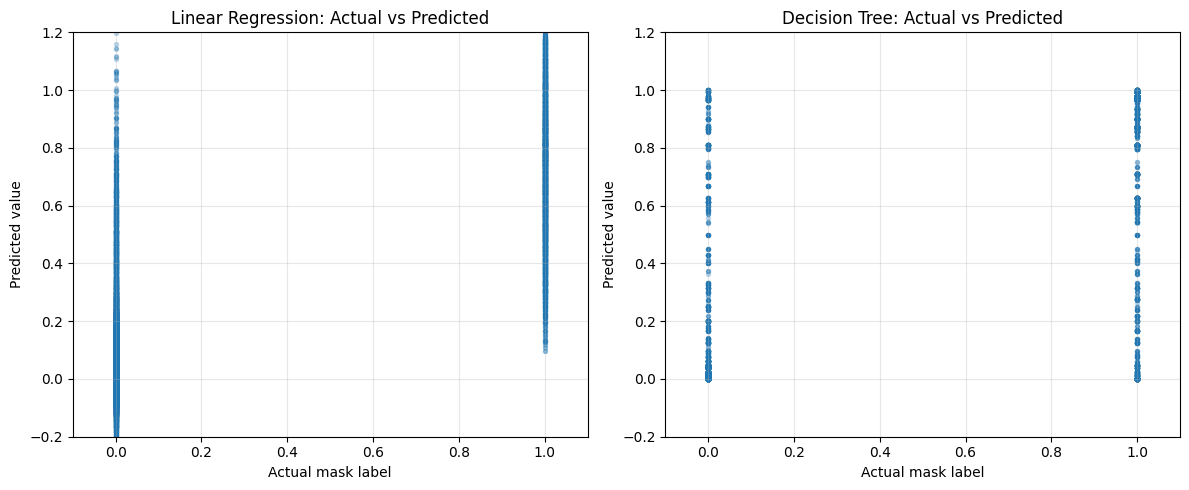

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(y_test, linear_predictions, alpha=0.25, s=8)
axes[0].set_title("Linear Regression: Actual vs Predicted")
axes[0].set_xlabel("Actual mask label")
axes[0].set_ylabel("Predicted value")

axes[1].scatter(y_test, tree_predictions, alpha=0.25, s=8)
axes[1].set_title("Decision Tree: Actual vs Predicted")
axes[1].set_xlabel("Actual mask label")
axes[1].set_ylabel("Predicted value")

for ax in axes:
    ax.set_xlim(-0.1, 1.1)
    ax.set_ylim(-0.2, 1.2)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Comparison of Model Performance

| Metric | Linear Regression | Decision Tree Regression |
| ------ | ----------------: | -----------------------: |
| MAE    |            0.1852 |                   0.0907 |
| RMSE   |            0.2652 |                   0.2498 |
| R²     |            0.6455 |                   0.6854 |

The Decision Tree Regression model performed better than Linear Regression across all three evaluation metrics. It achieved a lower Mean Absolute Error (MAE) of 0.0907 compared to 0.1852 for Linear Regression. Its Root Mean Squared Error (RMSE) was also lower, at 0.2498 compared to 0.2652. Furthermore, the Decision Tree achieved a higher R² value of 0.6854, while Linear Regression recorded 0.6455.

These results suggest that the Decision Tree model captured patterns in the Landslide4Sense dataset more effectively than Linear Regression. This may be because decision trees can model nonlinear relationships between spectral bands, slope, elevation, and landslide labels. Therefore, the Decision Tree Regression model was the better-performing model in this experiment.


